<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

XOR Predictions:
[[0]
 [1]
 [1]
 [0]]
Actual Output:
[[0]
 [1]
 [1]
 [0]]


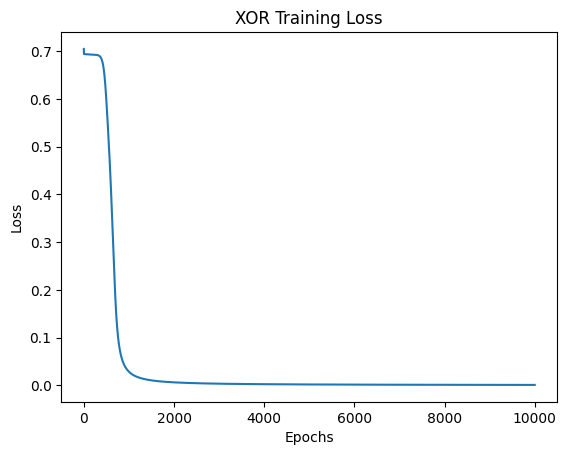

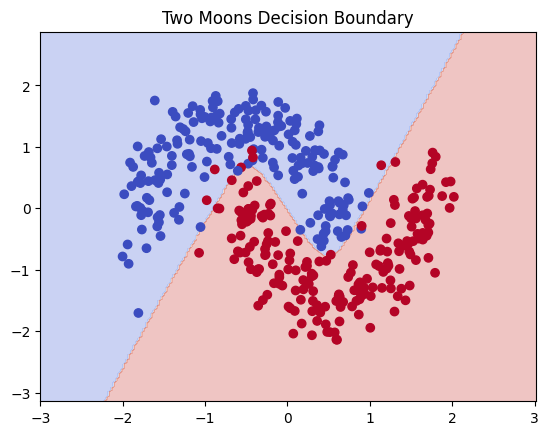

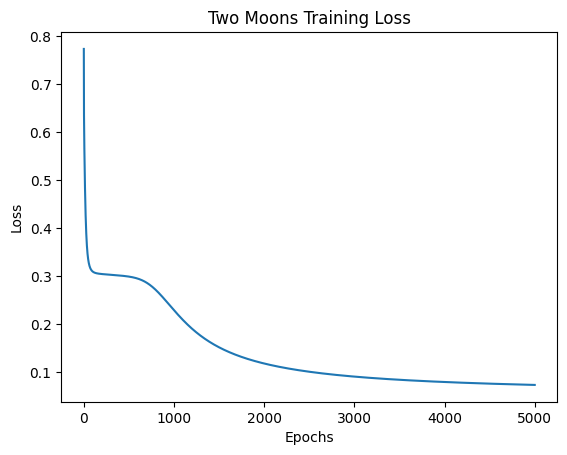

Numerical Gradient: 0.05507754060052327


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
np.random.seed(42)

# Activation Function
def sigmoid(x):
    return 1/(1+np.exp(-np.clip(x,-40,40)))

# 1. Neural Network Training
def train_network(X,Y,hidden=8,epochs=3000,lr=0.5):

    n,d = X.shape

    W1 = np.random.randn(d,hidden)*0.5
    b1 = np.zeros((1,hidden))

    W2 = np.random.randn(hidden,1)*0.5
    b2 = np.zeros((1,1))

    losses = []

    for epoch in range(epochs):

        # 2. Forward Propagation
        z1 = X@W1+b1
        a1 = sigmoid(z1)

        z2 = a1@W2+b2
        a2 = sigmoid(z2)

        loss = -np.mean(
            Y*np.log(a2+1e-9)
            +(1-Y)*np.log(1-a2+1e-9)
        )

        losses.append(loss)

        # 3. Backpropagation
        dz2 = (a2-Y)/n

        dW2 = a1.T@dz2
        db2 = np.sum(dz2,axis=0,keepdims=True)

        dz1 = (dz2@W2.T)*a1*(1-a1)

        dW1 = X.T@dz1
        db1 = np.sum(dz1,axis=0,keepdims=True)

        # Gradient Descent
        W1 -= lr*dW1
        b1 -= lr*db1

        W2 -= lr*dW2
        b2 -= lr*db2

    return W1,b1,W2,b2,losses

# Prediction
def predict(params,X):

    W1,b1,W2,b2 = params

    a1 = sigmoid(X@W1+b1)
    a2 = sigmoid(a1@W2+b2)

    return (a2>=0.5).astype(int)

# 4. XOR Dataset
X = np.array([
    [0,0],
    [0,1],
    [1,0],
    [1,1]
])

Y = np.array([[0],[1],[1],[0]])

W1,b1,W2,b2,losses = train_network(
    X,Y,hidden=4,epochs=10000,lr=1.0
)

params = (W1,b1,W2,b2)

print("XOR Predictions:")
print(predict(params,X))

print("Actual Output:")
print(Y)

plt.plot(losses)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("XOR Training Loss")
plt.show()

# 5. Two Moons Dataset
X,Y = make_moons(
    n_samples=400,
    noise=0.18,
    random_state=42
)

X = StandardScaler().fit_transform(X)
Y = Y.reshape(-1,1)

W1,b1,W2,b2,losses = train_network(
    X,Y,hidden=12,epochs=5000,lr=0.5
)

params = (W1,b1,W2,b2)

# Decision Boundary
xx,yy = np.meshgrid(
    np.linspace(X[:,0].min()-1,X[:,0].max()+1,200),
    np.linspace(X[:,1].min()-1,X[:,1].max()+1,200)
)

grid = np.c_[xx.ravel(),yy.ravel()]

Z = predict(params,grid).reshape(xx.shape)

plt.contourf(xx,yy,Z,alpha=0.3,cmap='coolwarm')

plt.scatter(X[:,0],X[:,1],c=Y.ravel(),cmap='coolwarm')

plt.title("Two Moons Decision Boundary")
plt.show()

plt.plot(losses)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Two Moons Training Loss")
plt.show()

# Numerical Gradient Verification
epsilon = 1e-5

W_plus = W1.copy()
W_minus = W1.copy()

W_plus[0,0] += epsilon
W_minus[0,0] -= epsilon

def calculate_loss(W):
    a1 = sigmoid(X[:4]@W+b1)
    a2 = sigmoid(a1@W2+b2)
    return -np.mean(
        Y[:4]*np.log(a2+1e-9)
        +(1-Y[:4])*np.log(1-a2+1e-9)
    )

numerical = (
    calculate_loss(W_plus)-calculate_loss(W_minus)
)/(2*epsilon)

print("Numerical Gradient:",numerical)